# Détection de fraude par carte de crédit 


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    classification_report, roc_auc_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve, f1_score
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

import joblib
import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
os.makedirs("data_prepared", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("figures", exist_ok=True)  

In [3]:
data = pd.read_csv("credit/credit_card_fraud_2026.csv")
print(f"Dataset : {data.shape}")
print(f"Fraudes : {data['is_fraud'].sum()} ({data['is_fraud'].mean()*100:.2f}%)")
display(data.head())

Dataset : (20000, 26)
Fraudes : 339 (1.70%)


,transaction_id,amount_usd,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,...,ip_country_mismatch,billing_shipping_mismatch,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,is_ai_generated_scam_attempt,merchant_risk_score,prior_disputes,is_fraud
0,1,42.86,Restaurants,Visa,OTP,Online,Android Phone,False,13.54,2,...,False,False,0,0.1,18,3,False,42.3,0,0
1,2,4.75,Online Retail,Mastercard,3D Secure,Online,Android Phone,False,0.71,2,...,False,False,0,25.8,12,4,False,28.3,0,0
2,3,77.18,Groceries,Mastercard,3D Secure,Online,Mac,False,0.35,5,...,False,True,0,42.3,5,0,False,24.7,1,0
3,4,1.69,Streaming,Visa,No Authentication,POS,Android Phone,False,3.42,6,...,False,False,0,28.9,22,6,False,56.2,1,0
4,5,261.68,Travel,Visa,3D Secure,In-App,iPhone,False,2.43,2,...,False,False,0,3.9,2,4,False,32.7,0,0


In [4]:
print(f"Lignes × Colonnes : {data.shape}\n")
print("Colonnes et types :")
print(data.dtypes.to_string())

Lignes × Colonnes : (20000, 26)

Colonnes et types :
transaction_id                    int64
amount_usd                      float64
merchant_category                   str
card_type                           str
auth_method                         str
channel                             str
device_type                         str
is_foreign_transaction             bool
hours_since_last_txn            float64
txn_count_last_24h                int64
distance_from_home_km           float64
card_age_months                   int64
customer_age                      int64
account_balance_usd             float64
is_new_merchant                    bool
used_vpn                           bool
ip_country_mismatch                bool
billing_shipping_mismatch          bool
cvv_retry_count                   int64
velocity_score                  float64
time_of_day_hour                  int64
day_of_week                       int64
is_ai_generated_scam_attempt       bool
merchant_risk_score        

In [5]:
missing = data.isnull().sum().sum()
dupes = data.duplicated().sum()
print(f"Valeurs manquantes : {missing}")
print(f"Doublons : {dupes}")

Valeurs manquantes : 0
Doublons : 0


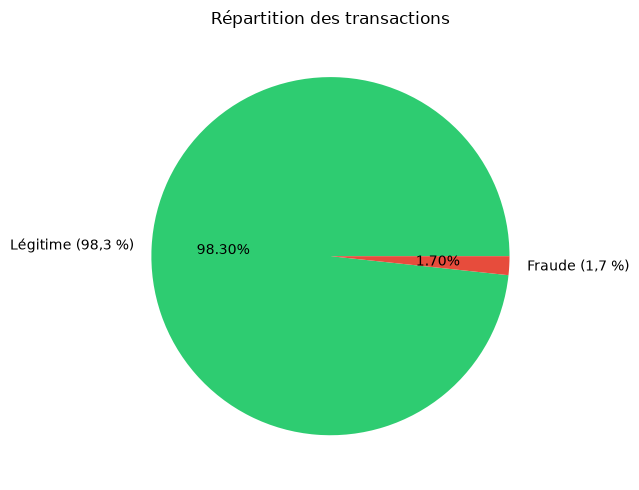

In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
data["is_fraud"].value_counts().plot(
    kind="pie",
    labels=["Légitime (98,3 %)", "Fraude (1,7 %)"],
    colors=["#2ecc71", "#e74c3c"],
    autopct="%1.2f%%",
    ax=ax,
)
ax.set_title("Répartition des transactions")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("figures/01_desequilibre.png", dpi=120, bbox_inches="tight")
plt.show()

In [7]:
num_cols_eda = data.select_dtypes(include=np.number).columns.drop("transaction_id")
display(data[num_cols_eda].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
amount_usd,20000.0,132.42,256.96,1.00,26.24,57.51,131.75,6872.69
hours_since_last_txn,20000.0,8.95,8.84,0.01,2.59,6.21,12.43,87.05
txn_count_last_24h,20000.0,3.19,1.78,0.00,2.00,3.00,4.00,12.00
distance_from_home_km,20000.0,22.14,22.12,0.00,6.34,15.50,30.82,216.19
card_age_months,20000.0,46.94,6.77,22.00,42.00,47.00,51.00,74.00
customer_age,20000.0,49.67,18.49,18.00,34.00,50.00,66.00,81.00
account_balance_usd,20000.0,3316.66,4350.72,52.05,1019.14,2007.68,3944.12,127125.86
cvv_retry_count,20000.0,0.18,0.42,0.00,0.00,0.00,0.00,3.00
velocity_score,20000.0,19.81,12.37,0.00,10.70,18.80,27.60,74.40
time_of_day_hour,20000.0,11.53,6.93,0.00,6.00,12.00,18.00,23.00


13 variables numériques : ['amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes']


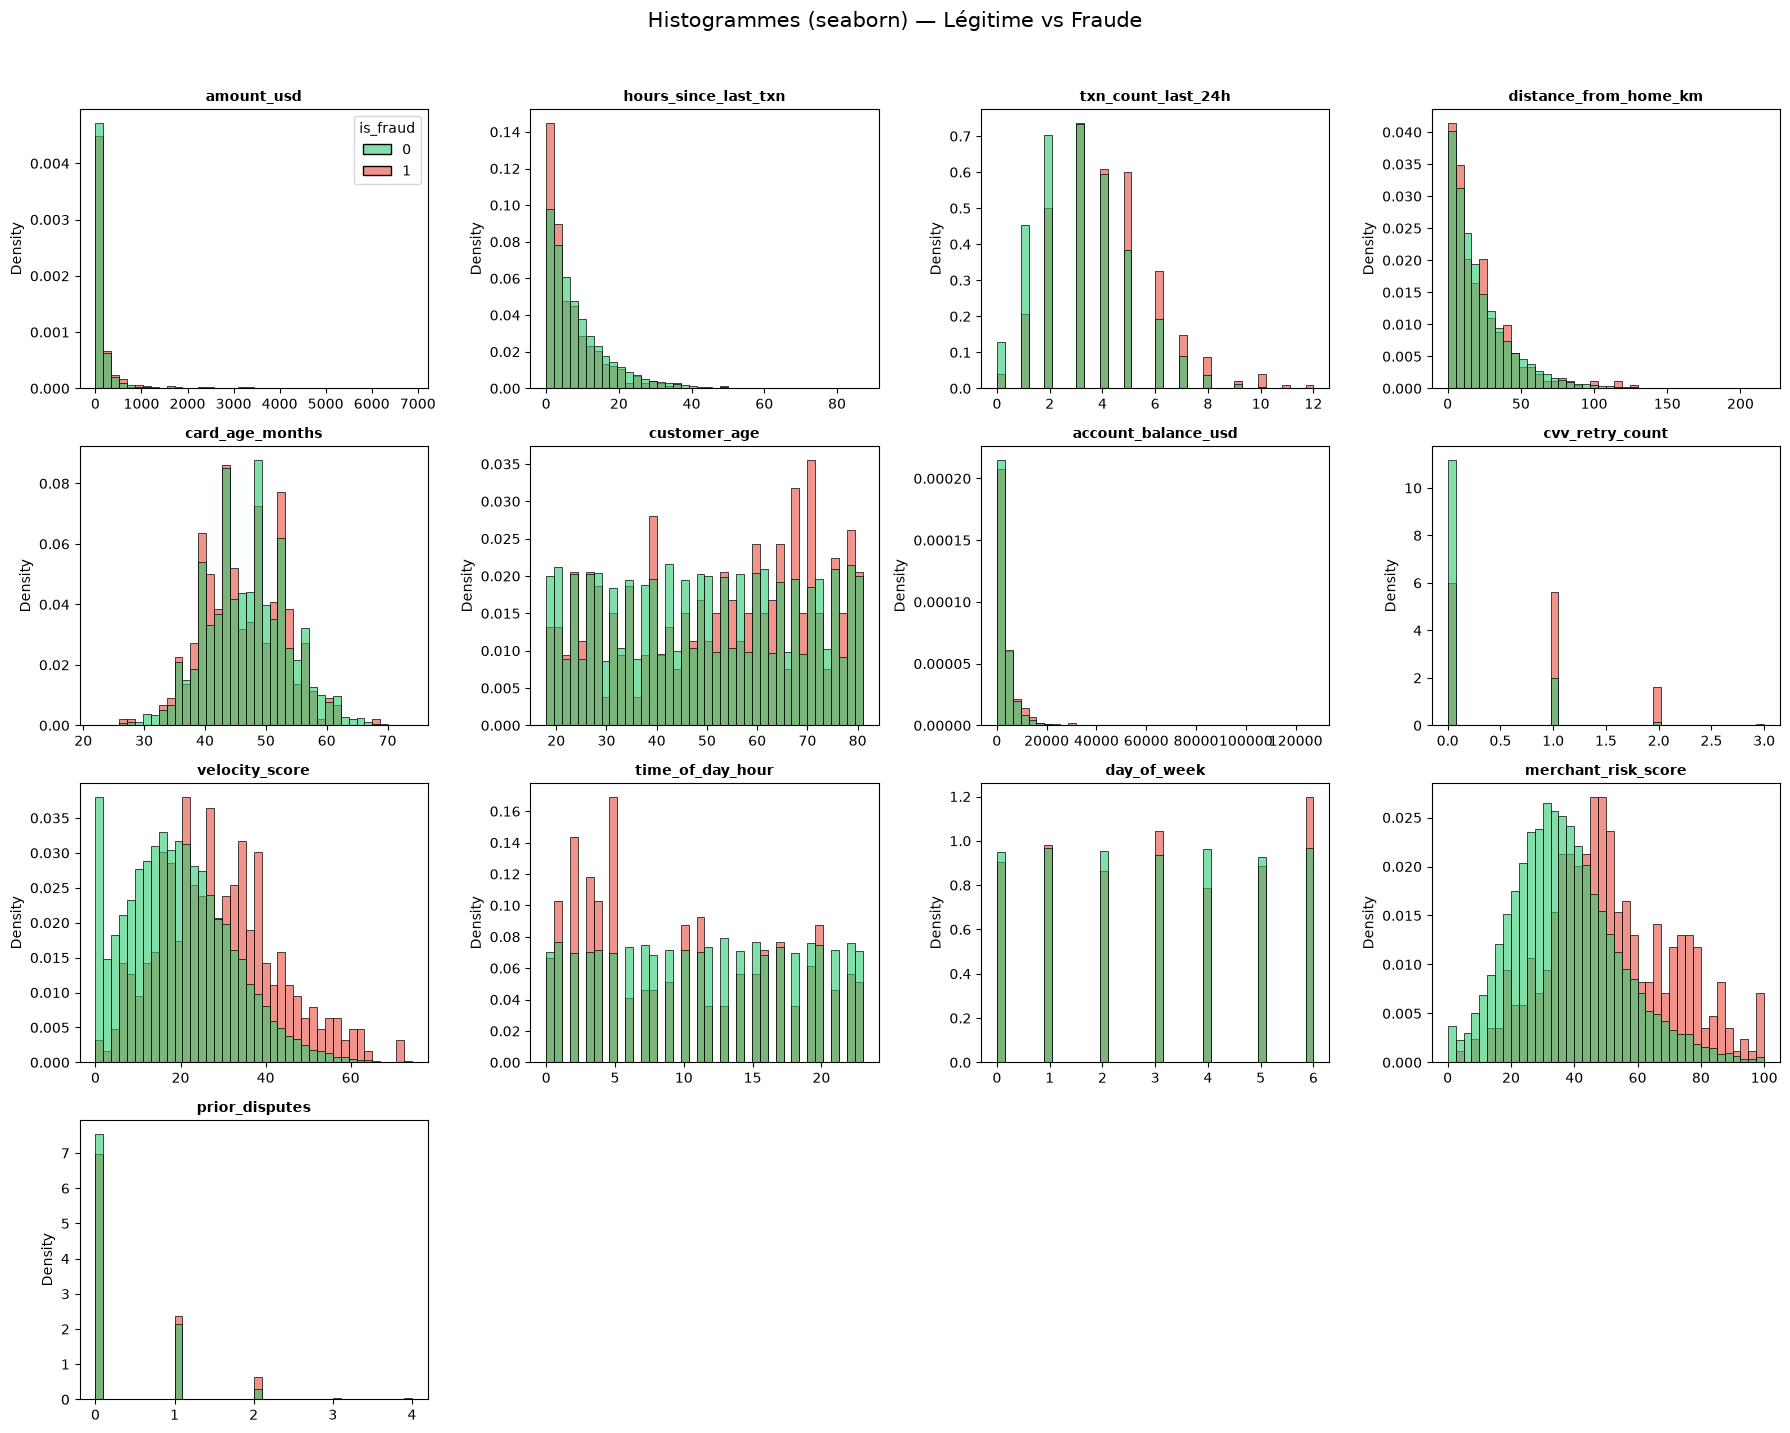

In [8]:
# On récupère toutes les colonnes numériques sauf cible et id
num_cols = data.select_dtypes(include=np.number).columns.tolist()
num_cols = [c for c in num_cols if c not in ["is_fraud", "transaction_id"]]
print(f"{len(num_cols)} variables numériques :", num_cols)

n = len(num_cols)
ncols = 4
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 3.5 * nrows))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(
        data=data, x=col, hue="is_fraud",
        bins=40, stat="density", common_norm=False,
        palette={0: "#2ecc71", 1: "#e74c3c"},
        alpha=0.6, ax=axes[i], legend=(i == 0)
    )
    axes[i].set_title(col, fontsize=10, fontweight="bold")
    axes[i].set_xlabel("")

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.suptitle("Histogrammes (seaborn) — Légitime vs Fraude", fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig("figures/histogrammes.png", dpi=120, bbox_inches="tight")
plt.show()

6 booléens : ['is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']


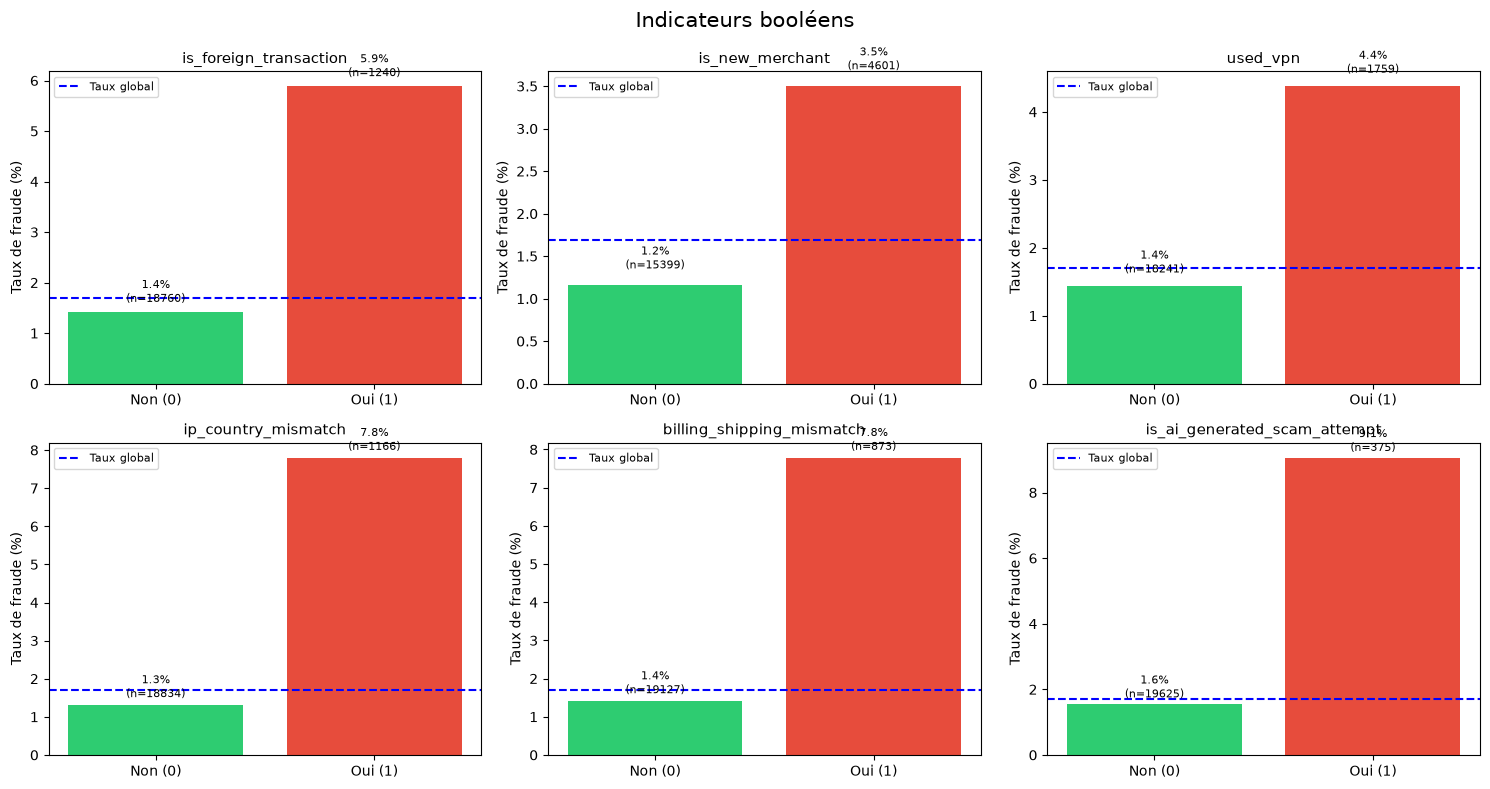

In [9]:
bool_cols = data.select_dtypes(include="bool").columns.tolist()
print(f"{len(bool_cols)} booléens :", bool_cols)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(bool_cols):
    taux = data.groupby(col)["is_fraud"].mean() * 100
    effectif = data.groupby(col)["is_fraud"].count()
    axes[i].bar(["Non (0)", "Oui (1)"], taux.values, color=["#2ecc71", "#e74c3c"])
    axes[i].axhline(data["is_fraud"].mean() * 100, color="blue", ls="--", label="Taux global")
    axes[i].set_title(col, fontsize=11)
    axes[i].set_ylabel("Taux de fraude (%)")
    for j, v in enumerate(taux.values):
        axes[i].text(j, v + 0.2, f"{v:.1f}%\n(n={effectif.iloc[j]})", ha="center", fontsize=8)
    axes[i].legend(fontsize=8)

plt.suptitle("Indicateurs booléens", fontsize=15)
plt.tight_layout()
plt.savefig("figures/booléens.png", dpi=120, bbox_inches="tight")
plt.show()

5 catégorielles : ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']


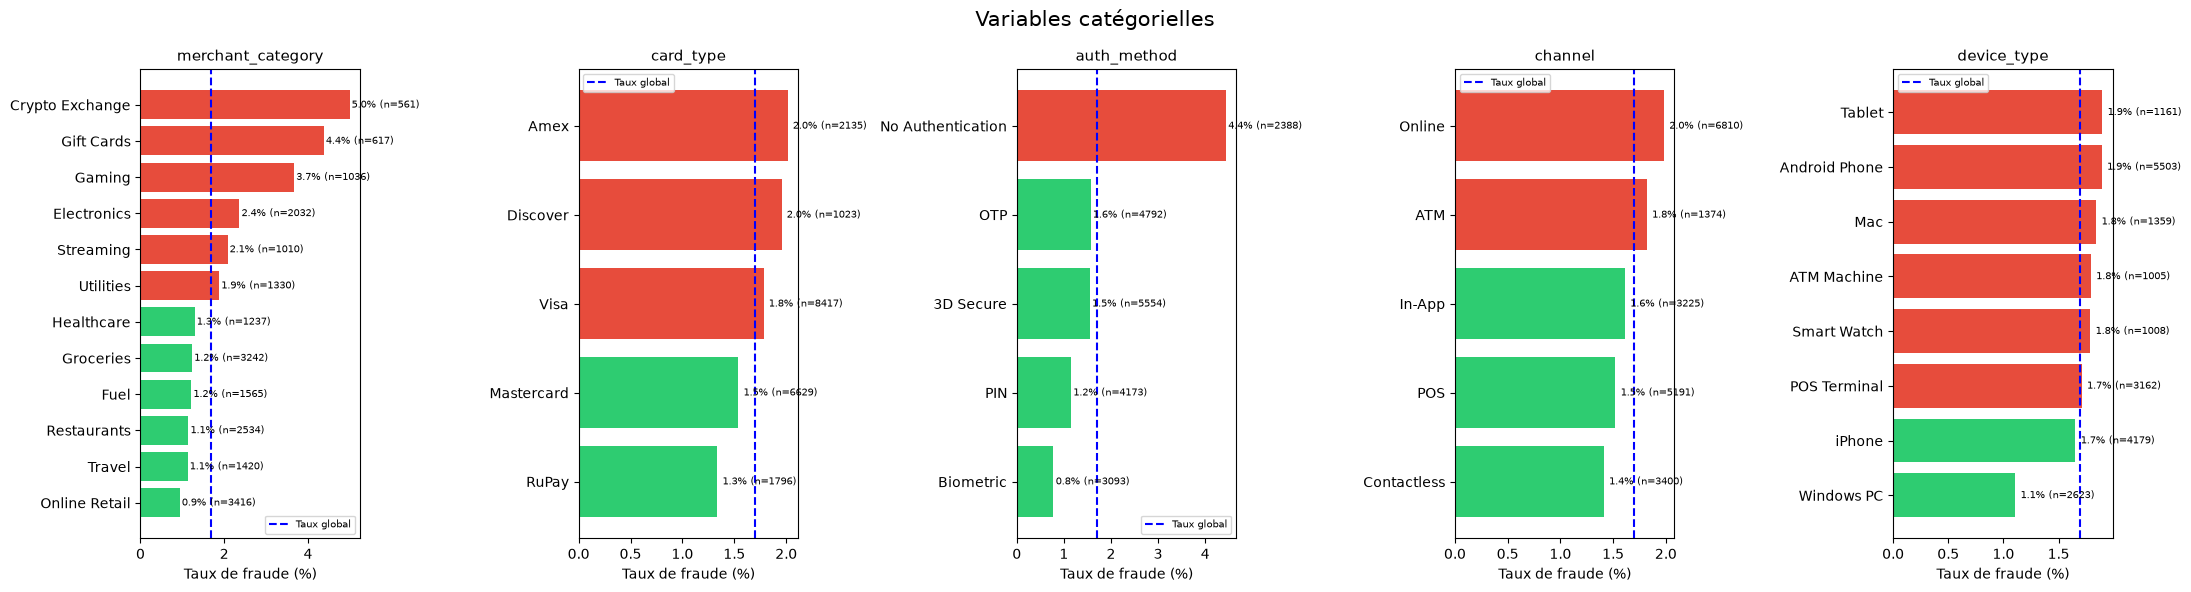

In [10]:
cat_cols = data.select_dtypes(include=["object", "str"]).columns.tolist()
print(f"{len(cat_cols)} catégorielles :", cat_cols)

fig, axes = plt.subplots(1, 5, figsize=(22, 6))

for i, col in enumerate(cat_cols):
    taux = data.groupby(col)["is_fraud"].mean().sort_values() * 100
    effectif = data.groupby(col)["is_fraud"].count()
    colors = ["#e74c3c" if v > data["is_fraud"].mean()*100 else "#2ecc71" for v in taux.values]
    axes[i].barh(taux.index.astype(str), taux.values, color=colors)
    axes[i].axvline(data["is_fraud"].mean() * 100, color="blue", ls="--", label="Taux global")
    axes[i].set_title(col, fontsize=11)
    axes[i].set_xlabel("Taux de fraude (%)")
    for j, (idx, v) in enumerate(taux.items()):
        axes[i].text(v + 0.05, j, f"{v:.1f}% (n={effectif[idx]})", va="center", fontsize=7)
    axes[i].legend(fontsize=7)

plt.suptitle("Variables catégorielles", fontsize=15)
plt.tight_layout()
plt.savefig("figures/catégorielles.png", dpi=120, bbox_inches="tight")
plt.show()

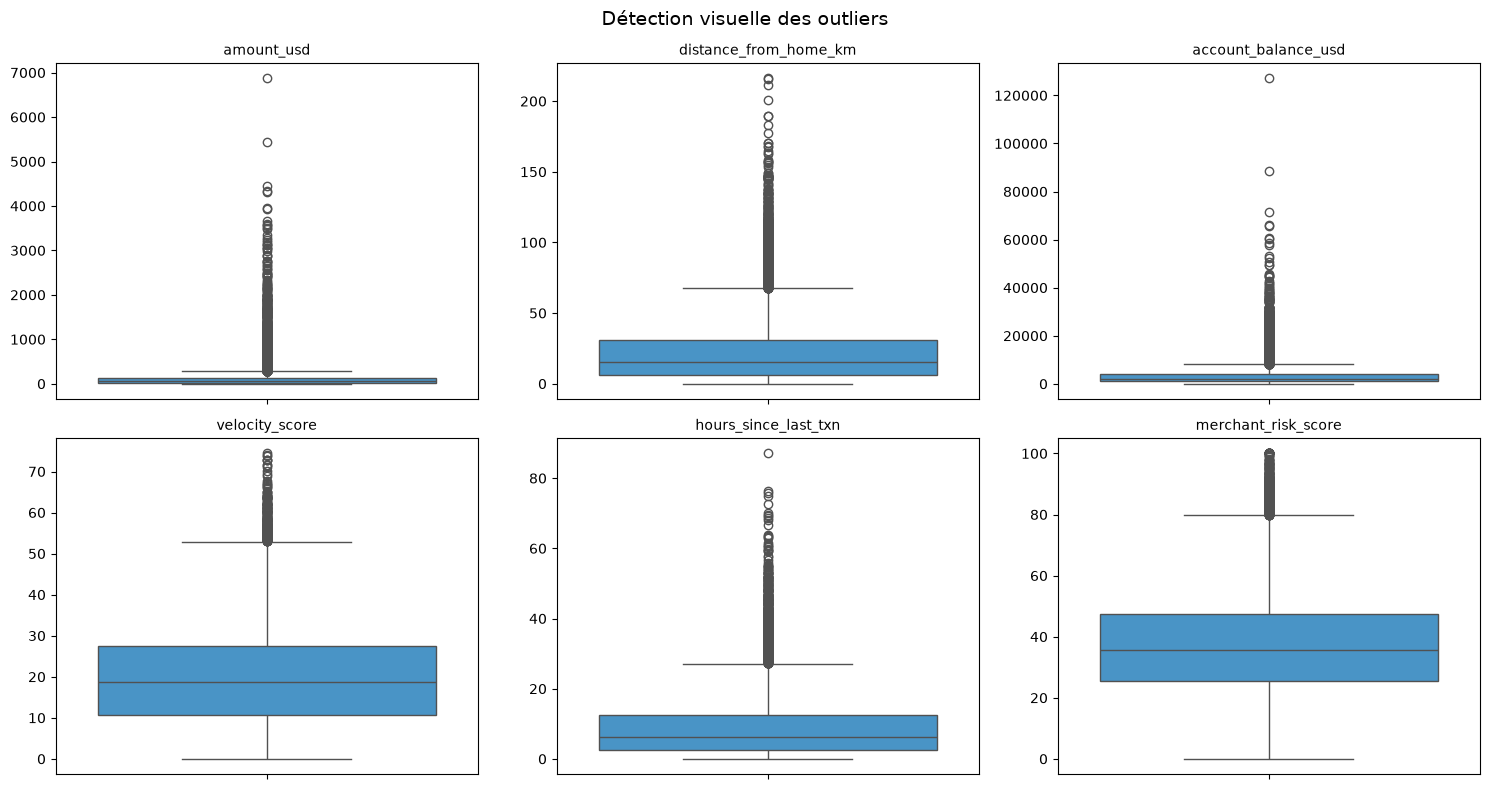


Proportion d'outliers :

  amount_usd                :  2061 outliers (10.30%)
  distance_from_home_km     :   904 outliers (4.52%)
  account_balance_usd       :  1569 outliers (7.85%)
  velocity_score            :   213 outliers (1.06%)
  hours_since_last_txn      :   955 outliers (4.78%)
  merchant_risk_score       :   358 outliers (1.79%)


In [19]:
# Boxplots des variables numériques continues
continuous_cols = [
    "amount_usd", "distance_from_home_km", "account_balance_usd",
    "velocity_score", "hours_since_last_txn", "merchant_risk_score"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(continuous_cols):
    sns.boxplot(y=data[col], ax=axes[i], color="#3498db")
    axes[i].set_title(col, fontsize=10)
    axes[i].set_ylabel("")

plt.suptitle("Détection visuelle des outliers", fontsize=14)
plt.tight_layout()
plt.savefig("figures/outliers_boxplots.png", dpi=120, bbox_inches="tight")
plt.show()

# Rapport quantitatif des outliers avec le quartile
print("\nProportion d'outliers :\n")
for col in continuous_cols:
    q1, q3 = data[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((data[col] < lower) | (data[col] > upper)).sum()
    print(f"  {col:<25} : {n_out:>5} outliers ({n_out/len(data)*100:.2f}%)")

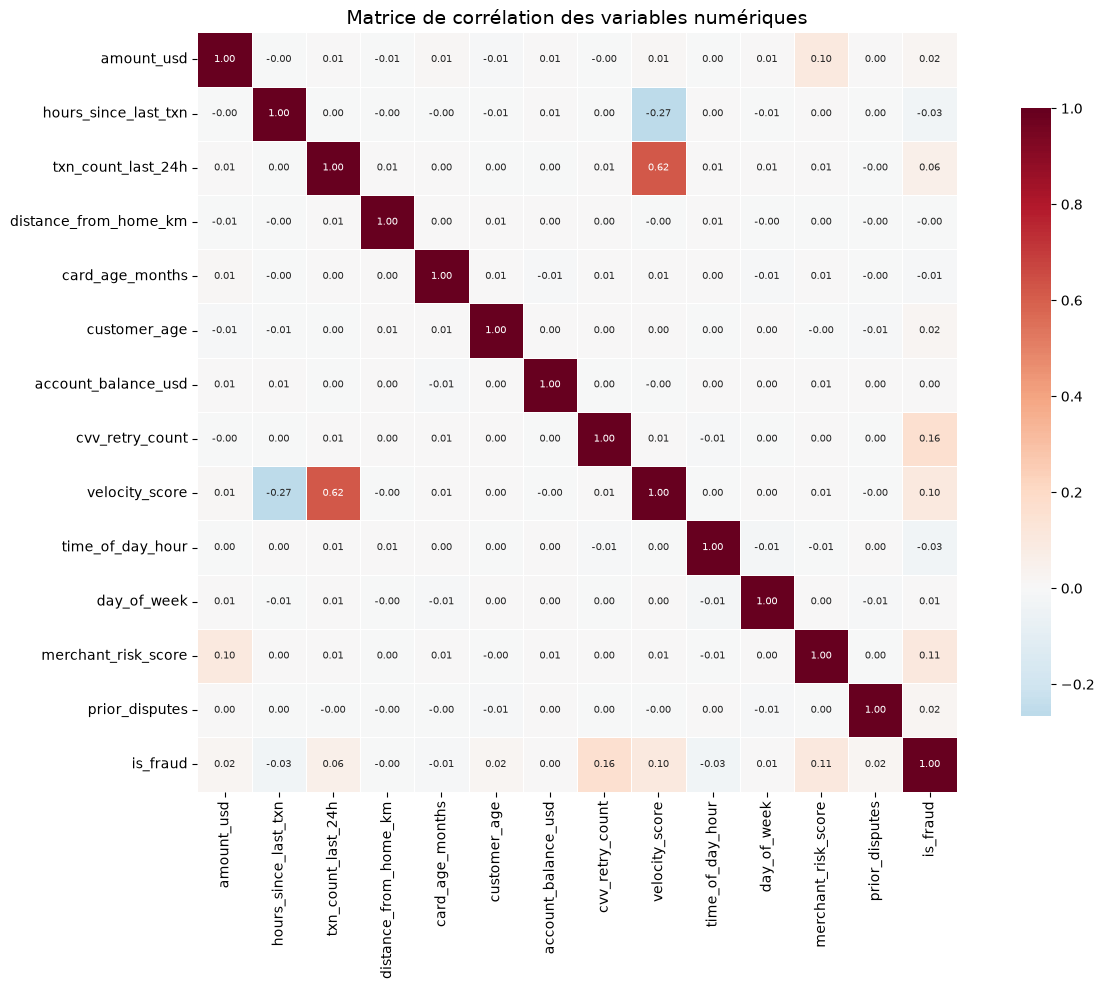


Corrélations avec is_fraud :

cvv_retry_count          0.155509
merchant_risk_score      0.107680
velocity_score           0.097255
txn_count_last_24h       0.059866
amount_usd               0.024951
prior_disputes           0.023903
customer_age             0.019543
day_of_week              0.006071
account_balance_usd      0.004371
distance_from_home_km   -0.004292
card_age_months         -0.012065
hours_since_last_txn    -0.028798
time_of_day_hour        -0.030814
Name: is_fraud, dtype: float64


In [12]:
# Matrice de corrélation des variables numériques avec la cible
num_cols_all = data.select_dtypes(include=np.number).columns.tolist()
num_cols_all = [c for c in num_cols_all if c != "transaction_id"]

corr_matrix = data[num_cols_all].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(
    corr_matrix,
    annot=True, fmt=".2f", cmap="RdBu_r",
    center=0, square=True, linewidths=0.5,
    cbar_kws={"shrink": 0.8}, annot_kws={"size": 7}
)
plt.title("Matrice de corrélation des variables numériques", fontsize=14)
plt.tight_layout()
plt.savefig("figures/correlation_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

# Corrélations avec la cible
print("\nCorrélations avec is_fraud :\n")
print(corr_matrix["is_fraud"].drop("is_fraud").sort_values(ascending=False))

# Prétraitement

In [ ]:
def engineer_features(df):
    """Crée des features dérivées"""
    df = df.copy()
    df["amount_to_balance_ratio"] = df["amount_usd"] / (df["account_balance_usd"] + 1)
    risk_flags = ["is_foreign_transaction", "is_new_merchant", "used_vpn",
                  "ip_country_mismatch", "billing_shipping_mismatch",
                  "is_ai_generated_scam_attempt"]
    df["risk_signal_count"] = df[risk_flags].sum(axis=1)
    df["txn_velocity"] = df["txn_count_last_24h"] / (df["hours_since_last_txn"] + 1)
    df["is_night"] = ((df["time_of_day_hour"] >= 0) & (df["time_of_day_hour"] <= 6)).astype(int)
    df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)
    df["card_age_ratio"] = df["card_age_months"] / (df["customer_age"] * 12 + 1)
    # Encodage cyclique 
    df["hour_sin"] = np.sin(2 * np.pi * df["time_of_day_hour"] / 24)
    df["hour_cos"] = np.cos(2 * np.pi * df["time_of_day_hour"] / 24)
    df["dow_sin"]  = np.sin(2 * np.pi * df["day_of_week"] / 7)
    df["dow_cos"]  = np.cos(2 * np.pi * df["day_of_week"] / 7)
    return df

data_eng = engineer_features(data)
new_features = [
    "amount_to_balance_ratio", "risk_signal_count", "txn_velocity",
    "is_night", "is_weekend", "card_age_ratio",
    "hour_sin", "hour_cos", "dow_sin", "dow_cos"
]
print(f"{len(new_features)} features créées")
print(f"Nouvelles dimensions : {data_eng.shape}")

10 features créées
Nouvelles dimensions : (20000, 36)


In [15]:
X = data_eng.drop(columns=["transaction_id", "is_fraud"])
y = data_eng["is_fraud"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print(f"Train : {X_train.shape} | Fraudes : {y_train.sum()} ({y_train.mean()*100:.2f}%)")
print(f"Test  : {X_test.shape} | Fraudes : {y_test.sum()} ({y_test.mean()*100:.2f}%)")

Train : (16000, 34) | Fraudes : 271 (1.69%)
Test  : (4000, 34) | Fraudes : 68 (1.70%)


In [16]:
num_cols  = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols  = X_train.select_dtypes(include=["object", "str"]).columns.tolist()
bool_cols = X_train.select_dtypes(include="bool").columns.tolist()

print(f"Num : {len(num_cols)} | Cat : {len(cat_cols)} | Bool : {len(bool_cols)}")

Num : 23 | Cat : 5 | Bool : 6


In [17]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num",  RobustScaler(), num_cols),
        ("cat",  OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("bool", "passthrough", bool_cols),
    ],
    remainder="drop",
)

In [18]:
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep  = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

print(f"Train prep : {X_train_prep.shape}")
print(f"Test  prep : {X_test_prep.shape}")


Train prep : (16000, 64)
Test  prep : (4000, 64)
